Name: Sahil Suresh Ghogare

Roll no.: 23102A0061

Branch / Div: BE CMPN A

R_Programming_Exp-7

**Importing Libraries**

In [10]:
install.packages(c(
  "readxl",
  "dplyr",
  "ggplot2",
  "cluster",
  "randomForest",
  "e1071",
  "pROC",
  "plotly",
  "caret"
))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



**Loading Libraries**

In [11]:
library(readxl)
library(dplyr)
library(ggplot2)
library(cluster)
library(randomForest)
library(e1071)
library(pROC)
library(plotly)
library(caret)

cat("Libraries loaded successfully")

Libraries loaded successfully

**Loading Dataset & Basic Information**

In [12]:
df <- read_excel("Online Retail.xlsx")

cat("Rows:", nrow(df), "\n")
cat("Columns:", ncol(df), "\n\n")

str(df)

cat("\nMissing Values:\n")
print(colSums(is.na(df)))

head(df)

Rows: 541909 
Columns: 8 

tibble [541,909 × 8] (S3: tbl_df/tbl/data.frame)
 $ InvoiceNo  : chr [1:541909] "536365" "536365" "536365" "536365" ...
 $ StockCode  : chr [1:541909] "85123A" "71053" "84406B" "84029G" ...
 $ Description: chr [1:541909] "WHITE HANGING HEART T-LIGHT HOLDER" "WHITE METAL LANTERN" "CREAM CUPID HEARTS COAT HANGER" "KNITTED UNION FLAG HOT WATER BOTTLE" ...
 $ Quantity   : num [1:541909] 6 6 8 6 6 2 6 6 6 32 ...
 $ InvoiceDate: POSIXct[1:541909], format: "2010-12-01 08:26:00" "2010-12-01 08:26:00" ...
 $ UnitPrice  : num [1:541909] 2.55 3.39 2.75 3.39 3.39 7.65 4.25 1.85 1.85 1.69 ...
 $ CustomerID : num [1:541909] 17850 17850 17850 17850 17850 ...
 $ Country    : chr [1:541909] "United Kingdom" "United Kingdom" "United Kingdom" "United Kingdom" ...

Missing Values:
  InvoiceNo   StockCode Description    Quantity InvoiceDate   UnitPrice 
          0           0        1454           0           0           0 
 CustomerID     Country 
     135080           0 


InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
<chr>,<chr>,<chr>,<dbl>,<dttm>,<dbl>,<dbl>,<chr>
536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850,United Kingdom


**Data Preprocessing**

In [13]:
df <- df %>%
  filter(!is.na(CustomerID)) %>%
  filter(!grepl("^C", InvoiceNo)) %>%
  filter(Quantity > 0, UnitPrice > 0) %>%
  distinct()

df$InvoiceDate <- as.POSIXct(df$InvoiceDate)

df$TotalAmount <- df$Quantity * df$UnitPrice

cat("Rows after preprocessing:", nrow(df), "\n")
cat("Customers:", length(unique(df$CustomerID)))

Rows after preprocessing: 392692 
Customers: 4338

**Customer-Level RFM Features**

In [14]:
reference_date <- max(df$InvoiceDate) + 86400

customer_data <- df %>%
  group_by(CustomerID) %>%
  summarise(
    Recency = as.numeric(
      difftime(reference_date, max(InvoiceDate), units="days")
    ),
    Frequency = n_distinct(InvoiceNo),
    MonetaryValue = sum(TotalAmount),
    AverageTransactionValue = mean(TotalAmount),
    TotalQuantity = sum(Quantity),
    FirstPurchase = min(InvoiceDate),
    LastPurchase = max(InvoiceDate)
  ) %>%
  mutate(
    TenureDays = as.numeric(
      difftime(LastPurchase, FirstPurchase, units="days")
    ) + 1,
    TenureMonths = TenureDays / 30,
    PurchaseFrequency = Frequency / ifelse(TenureMonths == 0, 1, TenureMonths)
  )

head(customer_data)

CustomerID,Recency,Frequency,MonetaryValue,AverageTransactionValue,TotalQuantity,FirstPurchase,LastPurchase,TenureDays,TenureMonths,PurchaseFrequency
<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dttm>,<dttm>,<dbl>,<dbl>,<dbl>
12346,326.117361,1,77183.60,77183.60000,74215,2011-01-18 10:01:00,2011-01-18 10:01:00,1.0000,0.03333333,30.0000000
12347,2.873611,7,4310.00,23.68132,2458,2010-12-07 14:57:00,2011-12-07 15:52:00,366.0382,12.20127315,0.5737106
12348,75.984028,4,1797.24,57.97548,2341,2010-12-16 19:09:00,2011-09-25 13:13:00,283.7528,9.45842593,0.4229033
12349,19.124306,1,1757.55,24.07603,631,2011-11-21 09:51:00,2011-11-21 09:51:00,1.0000,0.03333333,30.0000000
12350,310.867361,1,334.40,19.67059,197,2011-02-02 16:01:00,2011-02-02 16:01:00,1.0000,0.03333333,30.0000000
12352,36.925694,8,2506.04,29.48282,536,2011-02-16 12:33:00,2011-11-03 14:37:00,261.0861,8.70287037,0.9192369


**Selecting Features & Removing Outliers**

In [15]:
customer_features <- customer_data %>%
  select(
    Recency,
    Frequency,
    MonetaryValue,
    AverageTransactionValue,
    TotalQuantity,
    PurchaseFrequency
  )

# IQR-based outlier removal
Q1 <- apply(customer_features, 2, quantile, 0.25)
Q3 <- apply(customer_features, 2, quantile, 0.75)
IQR_val <- Q3 - Q1

lower <- Q1 - 1.5 * IQR_val
upper <- Q3 + 1.5 * IQR_val

keep <- apply(customer_features, 1, function(x)
  all(x >= lower & x <= upper)
)

customer_features <- customer_features[keep, ]

cat("Customers after outlier treatment:",
    nrow(customer_features))

Customers after outlier treatment: 3315

**Feature Scaling**

In [16]:
scaled_features <- scale(customer_features)

summary(scaled_features)

    Recency          Frequency       MonetaryValue     AverageTransactionValue
 Min.   :-0.9977   Min.   :-0.8427   Min.   :-1.0840   Min.   :-1.754684      
 1st Qu.:-0.7616   1st Qu.:-0.8427   1st Qu.:-0.7221   1st Qu.:-0.774919      
 Median :-0.4021   Median :-0.3809   Median :-0.3447   Median : 0.001694      
 Mean   : 0.0000   Mean   : 0.0000   Mean   : 0.0000   Mean   : 0.000000      
 3rd Qu.: 0.5543   3rd Qu.: 0.5427   3rd Qu.: 0.3946   3rd Qu.: 0.492678      
 Max.   : 2.6682   Max.   : 3.7754   Max.   : 3.6596   Max.   : 3.252862      
 TotalQuantity     PurchaseFrequency
 Min.   :-1.0524   Min.   :-0.8090  
 1st Qu.:-0.7311   1st Qu.:-0.7829  
 Median :-0.3717   Median :-0.7389  
 Mean   : 0.0000   Mean   : 0.0000  
 3rd Qu.: 0.4401   3rd Qu.: 1.1805  
 Max.   : 3.6050   Max.   : 3.2033  

**Elbow Method**

Selected K: 4

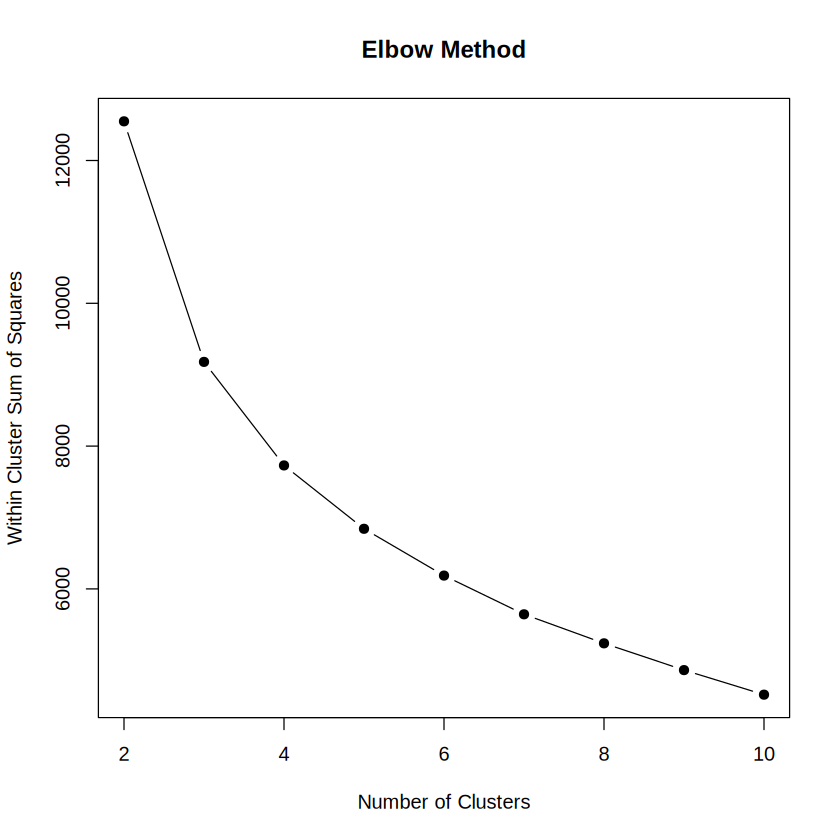

In [17]:
set.seed(42)

wss <- sapply(
  2:10,
  function(k) {
    kmeans(
      scaled_features,
      centers = k,
      nstart = 10
    )$tot.withinss
  }
)

plot(
  2:10,
  wss,
  type = "b",
  pch = 19,
  xlab = "Number of Clusters",
  ylab = "Within Cluster Sum of Squares",
  main = "Elbow Method"
)

optimal_k <- 4
cat("Selected K:", optimal_k)

**K-Means Clustering + Silhouette**

K-Means Silhouette Score: 0.3207 


   1    2    3    4 
 633  735  607 1340 


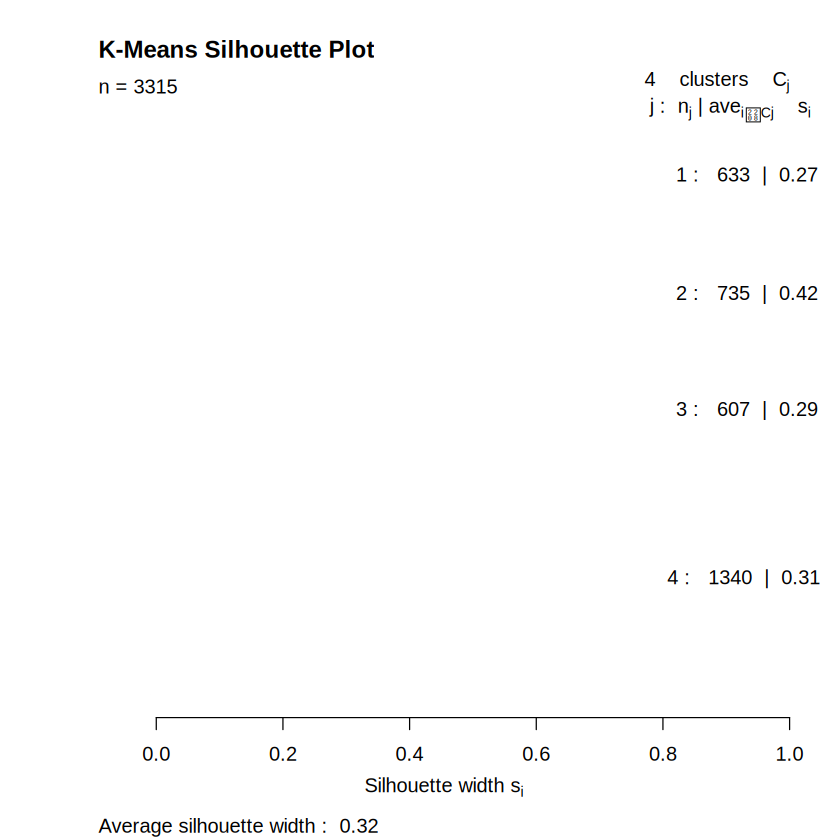

In [18]:
set.seed(42)

kmeans_model <- kmeans(
  scaled_features,
  centers = optimal_k,
  nstart = 25
)

customer_features$Cluster <-
  kmeans_model$cluster

sil_kmeans <- silhouette(
  customer_features$Cluster,
  dist(scaled_features)
)

kmeans_score <- mean(sil_kmeans[, 3])

cat("K-Means Silhouette Score:",
    round(kmeans_score, 4), "\n\n")

print(table(customer_features$Cluster))

plot(
  sil_kmeans,
  main = "K-Means Silhouette Plot"
)

**PCA 2D Visualization**

PC1 + PC2 variance: 71.46 %

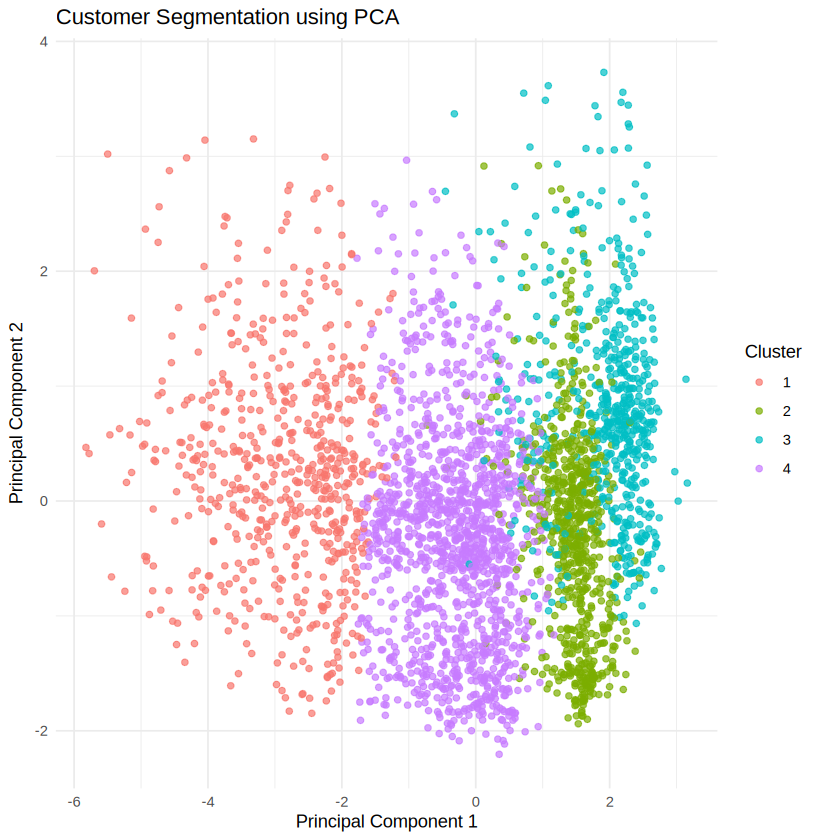

In [19]:
pca <- prcomp(
  scaled_features,
  center = FALSE,
  scale. = FALSE
)

pca_data <- data.frame(
  PC1 = pca$x[,1],
  PC2 = pca$x[,2],
  Cluster = as.factor(customer_features$Cluster)
)

ggplot(
  pca_data,
  aes(PC1, PC2, color=Cluster)
) +
  geom_point(alpha=0.7) +
  labs(
    title="Customer Segmentation using PCA",
    x="Principal Component 1",
    y="Principal Component 2"
  ) +
  theme_minimal()

cat(
  "PC1 + PC2 variance:",
  round(
    sum((pca$sdev^2 / sum(pca$sdev^2))[1:2]) * 100,
    2
  ),
  "%"
)

**Hierarchical Clustering + Dendrogram**

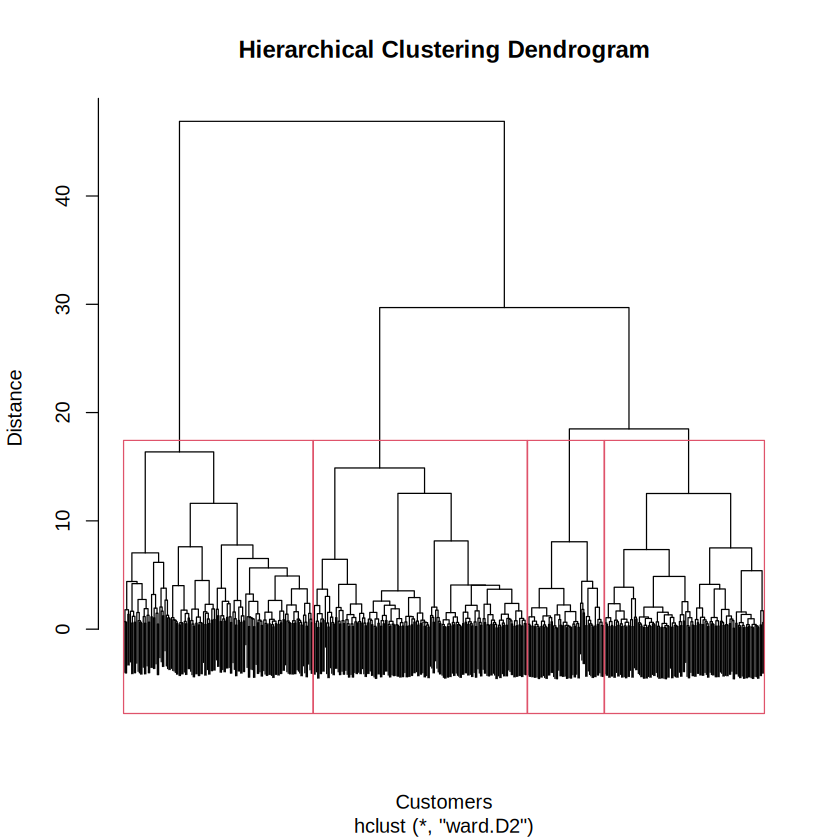

In [20]:
set.seed(42)

n <- min(500, nrow(scaled_features))
idx <- sample(1:nrow(scaled_features), n)

hier_data <- scaled_features[idx,]

hc <- hclust(
  dist(hier_data),
  method="ward.D2"
)

plot(
  hc,
  labels=FALSE,
  main="Hierarchical Clustering Dendrogram",
  xlab="Customers",
  ylab="Distance"
)

rect.hclust(
  hc,
  k=optimal_k
)

**Hierarchical Silhouette & Comparison**

In [21]:
hc_clusters <- cutree(
  hc,
  k=optimal_k
)

sil_hc <- silhouette(
  hc_clusters,
  dist(hier_data)
)

hc_score <- mean(sil_hc[,3])

comparison <- data.frame(
  Method=c(
    "K-Means",
    "Hierarchical"
  ),
  Silhouette_Score=c(
    kmeans_score,
    hc_score
  )
)

print(comparison)

        Method Silhouette_Score
1      K-Means        0.3206797
2 Hierarchical        0.2896480


**Cluster Profiling**

In [22]:
profile <- customer_features %>%
  group_by(Cluster) %>%
  summarise(
    CustomerCount=n(),
    AvgRecency=mean(Recency),
    AvgFrequency=mean(Frequency),
    AvgMonetaryValue=mean(MonetaryValue),
    AvgTransactionValue=mean(AverageTransactionValue),
    AvgQuantity=mean(TotalQuantity),
    AvgPurchaseFrequency=mean(PurchaseFrequency)
  )

print(profile)

# A tibble: 4 × 8
  Cluster CustomerCount AvgRecency AvgFrequency AvgMonetaryValue
    <int>         <int>      <dbl>        <dbl>            <dbl>
1       1           633       36.5         6.00            2151.
2       2           735       59.7         1.05             326.
3       3           607      247.          1.26             328.
4       4          1340       60.3         3.01             740.
# ℹ 3 more variables: AvgTransactionValue <dbl>, AvgQuantity <dbl>,
#   AvgPurchaseFrequency <dbl>


**Identify High-Value Customers**

In [23]:
high_value_cluster <- profile$Cluster[
  which.max(profile$AvgMonetaryValue)
]

customer_features$HighValue <- ifelse(
  customer_features$Cluster ==
    high_value_cluster,
  1,
  0
)

cat(
  "High-Value Cluster:",
  high_value_cluster,
  "\n\n"
)

print(
  table(customer_features$HighValue)
)

High-Value Cluster: 1 


   0    1 
2682  633 


**Train/Test Data**

In [24]:
prediction_data <- customer_features %>%
  select(
    Recency,
    Frequency,
    MonetaryValue,
    AverageTransactionValue,
    TotalQuantity,
    PurchaseFrequency,
    HighValue
  )

set.seed(42)

train_index <- createDataPartition(
  prediction_data$HighValue,
  p=0.8,
  list=FALSE
)

train <- prediction_data[train_index,]
test <- prediction_data[-train_index,]

cat("Training:", nrow(train), "\n")
cat("Testing:", nrow(test))

Training: 2652 
Testing: 663

**Random Forest**

In [25]:
set.seed(42)

rf <- randomForest(
  as.factor(HighValue) ~
    Recency +
    Frequency +
    MonetaryValue +
    AverageTransactionValue +
    TotalQuantity +
    PurchaseFrequency,
  data=train,
  ntree=100,
  importance=TRUE
)

rf_pred <- predict(rf, test)

rf_prob <- predict(
  rf,
  test,
  type="prob"
)[,2]

rf_cm <- confusionMatrix(
  rf_pred,
  as.factor(test$HighValue),
  positive="1"
)

rf_accuracy <- rf_cm$overall["Accuracy"]
rf_precision <- rf_cm$byClass["Precision"]
rf_recall <- rf_cm$byClass["Recall"]
rf_f1 <- rf_cm$byClass["F1"]
rf_auc <- as.numeric(
  auc(test$HighValue, rf_prob)
)

cat("Random Forest\n")
cat("Accuracy :", rf_accuracy, "\n")
cat("Precision:", rf_precision, "\n")
cat("Recall   :", rf_recall, "\n")
cat("F1 Score :", rf_f1, "\n")
cat("ROC-AUC  :", rf_auc, "\n")

Setting levels: control = 0, case = 1

Setting direction: controls < cases



Random Forest
Accuracy : 0.9894419 
Precision: 0.9738562 
Recall   : 0.9802632 
F1 Score : 0.9770492 
ROC-AUC  : 0.9994593 


**SVM**

In [26]:
svm_model <- svm(
  as.factor(HighValue) ~
    Recency +
    Frequency +
    MonetaryValue +
    AverageTransactionValue +
    TotalQuantity +
    PurchaseFrequency,
  data=train,
  kernel="radial",
  probability=TRUE
)

svm_pred <- predict(
  svm_model,
  test,
  probability=TRUE
)

svm_prob <- attr(
  svm_pred,
  "probabilities"
)[,"1"]

svm_cm <- confusionMatrix(
  svm_pred,
  as.factor(test$HighValue),
  positive="1"
)

svm_accuracy <- svm_cm$overall["Accuracy"]
svm_precision <- svm_cm$byClass["Precision"]
svm_recall <- svm_cm$byClass["Recall"]
svm_f1 <- svm_cm$byClass["F1"]
svm_auc <- as.numeric(
  auc(test$HighValue, svm_prob)
)

cat("SVM\n")
cat("Accuracy :", svm_accuracy, "\n")
cat("Precision:", svm_precision, "\n")
cat("Recall   :", svm_recall, "\n")
cat("F1 Score :", svm_f1, "\n")
cat("ROC-AUC  :", svm_auc, "\n")

Setting levels: control = 0, case = 1

Setting direction: controls < cases



SVM
Accuracy : 0.9969834 
Precision: 1 
Recall   : 0.9868421 
F1 Score : 0.9933775 
ROC-AUC  : 0.9999614 


**Model Comparison + Feature Importance**

          Model  Accuracy Precision    Recall  F1_Score   ROC_AUC
1 Random Forest 0.9894419 0.9738562 0.9802632 0.9770492 0.9994593
2           SVM 0.9969834 1.0000000 0.9868421 0.9933775 0.9999614
                                0         1 MeanDecreaseAccuracy
Recency                 -1.491324  8.856421             7.973257
Frequency                7.815982 17.910207            19.511852
MonetaryValue           12.792977 22.126093            23.051714
AverageTransactionValue  3.143216  5.728058             6.309297
TotalQuantity           16.273221 20.919235            25.842051
PurchaseFrequency       -1.423102  8.704957             8.333083
                        MeanDecreaseGini
Recency                         24.61795
Frequency                      129.26858
MonetaryValue                  297.86745
AverageTransactionValue         14.08910
TotalQuantity                  286.81384
PurchaseFrequency               34.23847


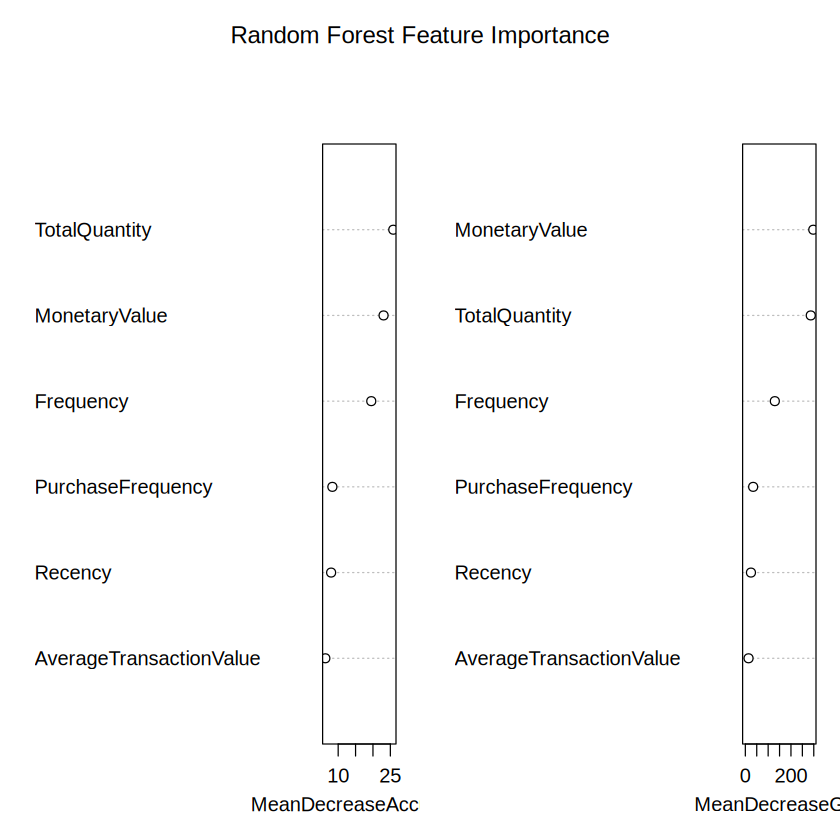

In [35]:
results <- data.frame(
  Model=c("Random Forest","SVM"),
  Accuracy=c(rf_accuracy, svm_accuracy),
  Precision=c(rf_precision, svm_precision),
  Recall=c(rf_recall, svm_recall),
  F1_Score=c(rf_f1, svm_f1),
  ROC_AUC=c(rf_auc, svm_auc)
)

print(results)

print(importance(rf))

varImpPlot(
  rf,
  main="Random Forest Feature Importance"
)

**Marketing Recommendations + Conclusion**

In [29]:
cat("CUSTOMER SEGMENT MARKETING RECOMMENDATIONS\n")
cat("============================================\n\n")

for(i in 1:nrow(profile)) {

  cluster <- profile$Cluster[i]

  cat("Cluster", cluster, "\n")

  if(cluster == high_value_cluster) {

    cat(
      "High-value customers.\n",
      "Recommendation: Loyalty rewards, exclusive offers, ",
      "premium products and personalized promotions.\n\n"
    )

  } else if(
    profile$AvgRecency[i] >
    median(profile$AvgRecency)
  ) {

    cat(
      "Less recently active customers.\n",
      "Recommendation: Re-engagement campaigns and discounts.\n\n"
    )

  } else if(
    profile$AvgFrequency[i] >
    median(profile$AvgFrequency)
  ) {

    cat(
      "Frequent customers.\n",
      "Recommendation: Loyalty benefits and repeat-purchase offers.\n\n"
    )

  } else {

    cat(
      "Lower-engagement customers.\n",
      "Recommendation: Introductory offers and product recommendations.\n\n"
    )
  }
}

cat("\nCONCLUSION\n")
cat("==========\n")
cat(
  "The Online Retail dataset was preprocessed and customer-level ",
  "RFM and purchasing features were generated. K-Means and ",
  "Hierarchical Clustering were used for customer segmentation. ",
  "PCA was applied for visualization and Silhouette Score was used ",
  "to evaluate clustering quality. The high-value customer segment ",
  "was identified and Random Forest and SVM models were developed ",
  "to predict high-value customers. Model performance was evaluated ",
  "using Accuracy, Precision, Recall, F1-Score and ROC-AUC. ",
  "Feature importance and interactive 3D visualization were also ",
  "performed, followed by targeted marketing recommendations."
)

CUSTOMER SEGMENT MARKETING RECOMMENDATIONS

Cluster 1 
High-value customers.
 Recommendation: Loyalty rewards, exclusive offers,  premium products and personalized promotions.

Cluster 2 
Lower-engagement customers.
 Recommendation: Introductory offers and product recommendations.

Cluster 3 
Less recently active customers.
 Recommendation: Re-engagement campaigns and discounts.

Cluster 4 
Less recently active customers.
 Recommendation: Re-engagement campaigns and discounts.


CONCLUSION
The Online Retail dataset was preprocessed and customer-level  RFM and purchasing features were generated. K-Means and  Hierarchical Clustering were used for customer segmentation.  PCA was applied for visualization and Silhouette Score was used  to evaluate clustering quality. The high-value customer segment  was identified and Random Forest and SVM models were developed  to predict high-value customers. Model performance was evaluated  using Accuracy, Precision, Recall, F1-Score and ROC-AUC.  Featu